# Committor Model: 1D Low-Friction Langevin Dynamics, with History

Trains a non-parametric committor (`CommittorNE`) on a long underdamped Langevin trajectory of a particle in 1D. At low friction the committor depends on position and velocity, q(λ, v), but only λ is given to the model. The velocity enters through the history: with lag d = 1 the basis is a polynomial in (λ(t−1), λ(t)), and with one frame per MD step that is equivalent to λ and the finite-difference velocity (λ(t) − λ(t−1))/dt.

**Data:** `md_istarwell2_100M/md_path.npy` (100M frames, one per step of dt = 0.005, columns λ and v; converted from `md_path.txt`). Friction γ = 1, kT = 1, m = 1.

**Potential:** `CosWellWalls`, a well of depth 1.2 kT on [−0.25, 0.25], flanked by 0.15 kT bumps and flat regions, with harmonic walls (k = 100) beyond ±0.45.

**Boundaries:** `λ <= -0.35` (A) and `λ >= 0.35` (B), the outer iSTAR interfaces

## 1. Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp

# Plot styling
plt.rc('font', size=10)
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=14)
plt.rc('xtick', labelsize=12)
plt.rc('ytick', labelsize=12)
plt.rc('legend', fontsize=12)

# Custom optimal-RC / committor package
import sys
sys.path.insert(0, '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/')
import optimalrcs, metrics, plots

## 2. Data Loading

Loads the first `n_frames` frames (5M frames contain about 8000 A↔B transitions). The velocity `v` is only used to check the result in section 6, not in training.

In [4]:
SRC = '/home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/md_istarwell2_100M'
n_frames = 6_000_000

data = np.load(f'{SRC}/md_path.npy', mmap_mode='r')[:n_frames]
lam, v = np.array(data[:, 0]), np.array(data[:, 1])
lambda_a, lambda_b = -0.35, 0.35
dt = 0.005                         # MD time step = time per frame
print(f'Frames: {len(lam)}')

Frames: 6000000


## 3. Free Energy Profile (FEP)

FEP along λ: the central well between the two small bumps.

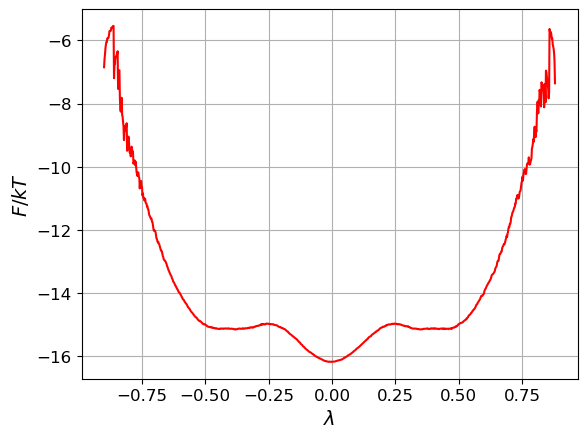

In [5]:
fig, ax = plt.subplots(1, 1)
plots.plot_fep(ax, cp.asarray(lam), xlabel='$\\lambda$')
plt.show()

## 4. Trajectory Indices

Single trajectory (`i_traj = 1` for all frames).

In [6]:
i_traj = np.ones_like(lam)          # trajectory index (1 = single trajectory)
t_traj = np.arange(len(lam))        # frame index

## 5. Train Committor (Non-Parametric), Several Seeds

`CommittorNE` rather than the equilibrium `Committor`: time reversal flips the velocity, so the reversible estimator does not apply to q(λ, v). The CVs are λ and the recorded velocity v; each iteration draws one of them.

The fit is repeated for every seed in `SEEDS` (the seed sets which CV and envelope centre each iteration draws). Each fit runs in chunks of `CHUNK` iterations; after every chunk the metrics, FEPs + Z_q and observed-vs-predicted plots and the (λ, v) map are saved to `figures/langevin_seeds/seed<s>/it<N>_*.png`, and the error against the brute-force reference q(x, v) is printed. `fit_transform` continues from the current RC on every call, so the chunks form one continuous run.

`lazy_basis=True` evaluates the basis in fused GPU kernels: about 4× faster here, same result. It is used instead of fewer frames: the statistical error of the comparison grows from 0.012 per bin at 6M frames to 0.020 at 2M.

**Parameters:**
| Parameter | Value | Description |
|-----------|-------|-------------|
| `SEEDS` | 0, 1, 2 | Random seeds |
| `MAX_ITER` | 30000 | Iterations per seed |
| `CHUNK` | 5000 | Iterations between saved plots |
| `envelope_scale` | 0.001 | RC envelope width |
| `gamma` | 0.1 | Regularization (scales the step; does not change the fixed point) |
| `ny` | 6 | Polynomial degree |

#=1000, xent=0.402824, mse=0.141814, sdzq=286.295, dzq=1150.8, dr2=8698.61, auc=0.865348, |dx|=0.175354, time=18.9716
#=2000, xent=0.401775, mse=0.141401, sdzq=252.957, dzq=1045.54, dr2=8811.72, auc=0.866294, |dx|=0.00751679, time=37.486
#=3000, xent=0.401241, mse=0.141153, sdzq=236.636, dzq=995.206, dr2=8861.51, auc=0.866857, |dx|=0.00427431, time=56.0552
#=4000, xent=0.400816, mse=0.140993, sdzq=224.581, dzq=957.268, dr2=8913.23, auc=0.867225, |dx|=0.00284223, time=74.6453
#=5000, xent=0.400517, mse=0.140853, sdzq=217.872, dzq=933.545, dr2=8946.09, auc=0.867526, |dx|=0.00246527, time=93.2337


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3311917/429165543.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')


seed 0, 5000 iterations: RMS(fit - exact) per frame 0.0596, plots in figures/langevin_seeds/seed0
#=6000, xent=0.400248, mse=0.140753, sdzq=211.245, dzq=915.114, dr2=8976.99, auc=0.86774, |dx|=0.00173778, time=18.5107
#=7000, xent=0.399995, mse=0.140648, sdzq=203.852, dzq=895.305, dr2=9010.32, auc=0.867946, |dx|=0.001786, time=37.0371
#=8000, xent=0.399764, mse=0.140564, sdzq=198.5, dzq=880.541, dr2=9032.81, auc=0.868131, |dx|=0.0016023, time=55.5547
#=9000, xent=0.39965, mse=0.1405, sdzq=193.981, dzq=867.813, dr2=9052.02, auc=0.868271, |dx|=0.00120357, time=74.0793
#=10000, xent=0.399496, mse=0.140438, sdzq=188.694, dzq=850.791, dr2=9073.49, auc=0.868398, |dx|=0.00108809, time=92.589


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3311917/429165543.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')


seed 0, 10000 iterations: RMS(fit - exact) per frame 0.0546, plots in figures/langevin_seeds/seed0
#=11000, xent=0.399372, mse=0.140392, sdzq=186.539, dzq=845.24, dr2=9088.53, auc=0.868493, |dx|=0.000946829, time=18.466
#=12000, xent=0.39935, mse=0.140356, sdzq=183.543, dzq=835.051, dr2=9095.56, auc=0.868569, |dx|=0.000824523, time=36.9732
#=13000, xent=0.399252, mse=0.140311, sdzq=180.593, dzq=827.408, dr2=9105.82, auc=0.868669, |dx|=0.000877809, time=55.4766
#=14000, xent=0.399062, mse=0.140265, sdzq=177.812, dzq=819.359, dr2=9125.74, auc=0.868765, |dx|=0.000924452, time=73.9879
#=15000, xent=0.399069, mse=0.140236, sdzq=175.325, dzq=810.939, dr2=9133.2, auc=0.868829, |dx|=0.000686152, time=92.4933


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3311917/429165543.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')


... (3 outputs left out)

/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3311917/429165543.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')


seed 1, 10000 iterations: RMS(fit - exact) per frame 0.0199, plots in figures/langevin_seeds/seed1
#=11000, xent=0.39497, mse=0.138517, sdzq=40.4811, dzq=211.651, dr2=10119.1, auc=0.873541, |dx|=0.000387462, time=37.8578
#=12000, xent=0.394952, mse=0.138512, sdzq=39.7629, dzq=207.451, dr2=10120.5, auc=0.873552, |dx|=0.000287819, time=75.8872
#=13000, xent=0.394934, mse=0.138508, sdzq=39.0297, dzq=203.169, dr2=10122.3, auc=0.873562, |dx|=0.000249667, time=113.916
#=14000, xent=0.394921, mse=0.138505, sdzq=38.4031, dzq=199.536, dr2=10123.6, auc=0.873572, |dx|=0.000256325, time=152.047
#=15000, xent=0.394916, mse=0.138502, sdzq=37.7101, dzq=195.585, dr2=10125.3, auc=0.873579, |dx|=0.000221073, time=190.231


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3311917/429165543.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')


seed 1, 15000 iterations: RMS(fit - exact) per frame 0.0191, plots in figures/langevin_seeds/seed1


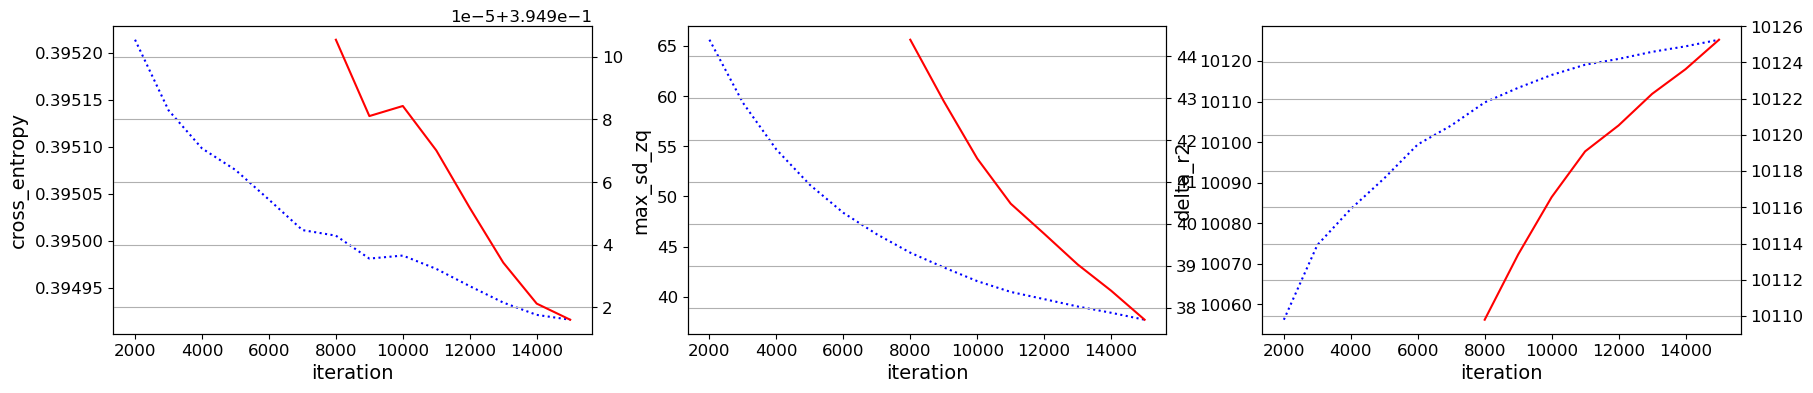

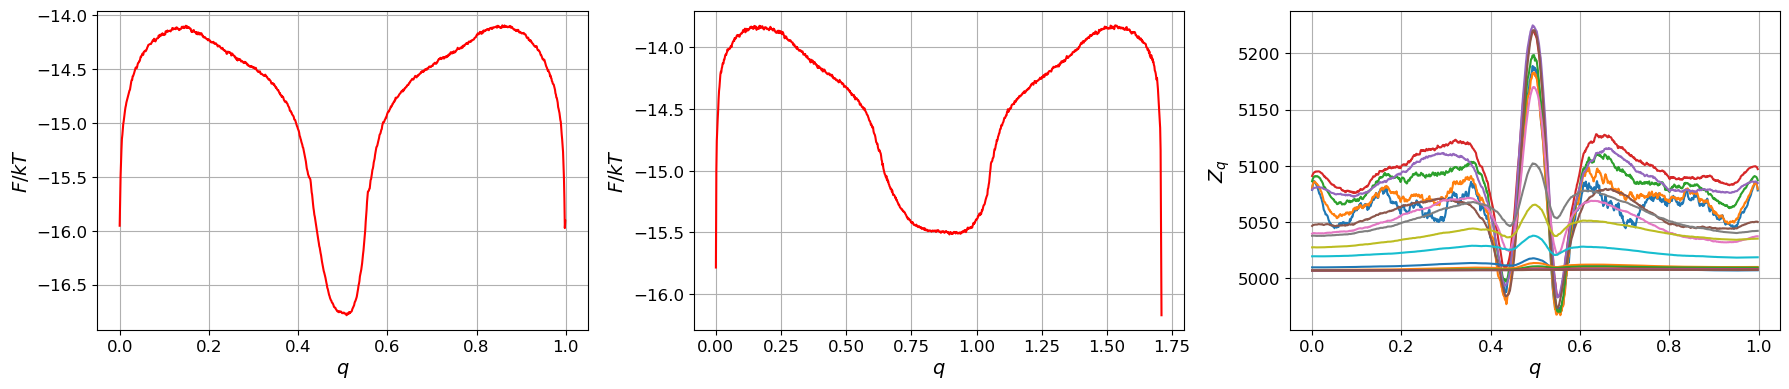

/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/conda_envs/RL/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


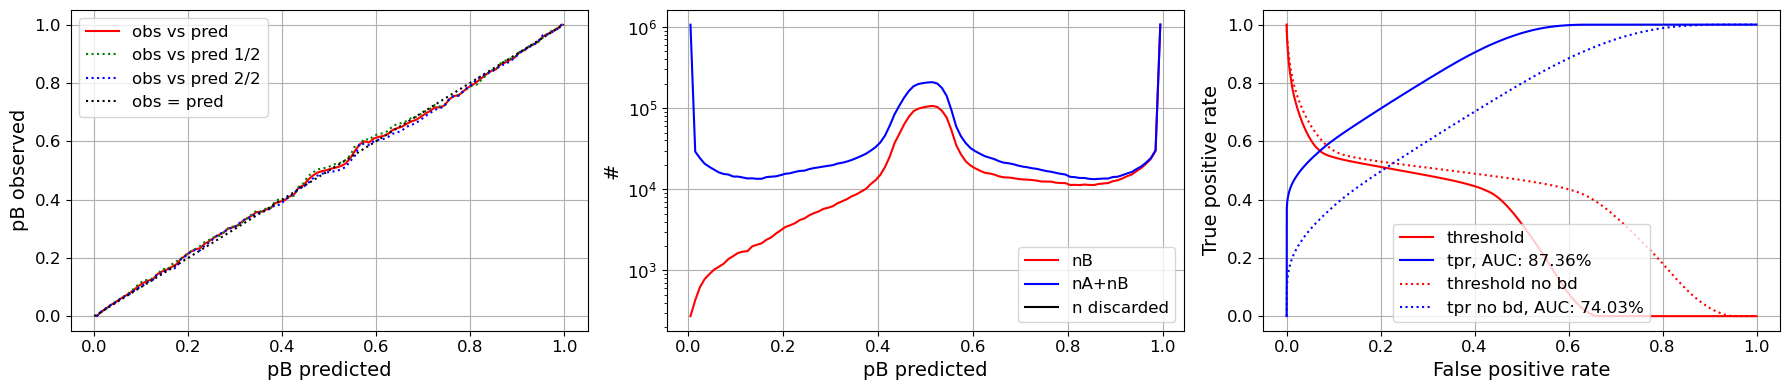

In [7]:
import os
from scipy.interpolate import RegularGridInterpolator

SEEDS = [0, 1]
MAX_ITER = 15000
CHUNK = 5000
OUT = 'figures/langevin_seeds'

optimalrcs.envelope_scale = 1
gamma = 0.1                        # regularization strength
Y = cp.asarray(np.c_[lam, v])      # CVs: lambda and the recorded velocity

# brute-force reference q(x, v), for the progress printout
ref = np.load('figures/well_check/reference.npz')
f_ref = RegularGridInterpolator((ref['xs'], ref['vs']), ref['q'], bounds_error=False, fill_value=None)
q_exact = np.clip(f_ref(np.c_[np.clip(lam, ref['xs'][0], ref['xs'][-1]), np.clip(v, ref['vs'][0], ref['vs'][-1])]), 0, 1)
free = (lam > lambda_a) & (lam < lambda_b)
edges_l, edges_v = np.linspace(lambda_a, lambda_b, 71), np.linspace(-3, 3, 61)
n_lv = np.histogram2d(lam, v, [edges_l, edges_v])[0]

def save_plots(q, folder, tag):
    # the library's plot methods call plt.show(); keep the figures open to save them instead
    show, plt.show = plt.show, (lambda *a, **k: None)
    try:
        q.plots_metrics(['cross_entropy', 'max_sd_zq', 'delta_r2'])
        plt.gcf().savefig(f'{folder}/{tag}_metrics.png', dpi=100); plt.close('all')
        q.plots_feps(delta_t_sim=dt)
        plt.gcf().savefig(f'{folder}/{tag}_feps.png', dpi=100); plt.close('all')
        q.plots_obs_pred()
        plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')
        r = cp.asnumpy(q.r_traj)
        s = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)[0]
        fig, ax = plt.subplots(figsize=(7, 5))
        im = ax.pcolormesh(edges_l, edges_v, np.where(n_lv > 20, s / np.maximum(n_lv, 1), np.nan).T,
                           cmap='coolwarm', vmin=0, vmax=1)
        fig.colorbar(im, ax=ax, label='$q$'); ax.set(xlabel='$\\lambda$', ylabel='$v$', title=tag)
        fig.savefig(f'{folder}/{tag}_q_lambda_v.png', dpi=100); plt.close('all')
    finally:
        plt.show = show
    return r

results = {}
for seed in SEEDS:
    folder = f'{OUT}/seed{seed}'
    os.makedirs(folder, exist_ok=True)
    np.random.seed(seed); cp.random.seed(seed)
    q = optimalrcs.CommittorNE(
        boundary0=lam <= lambda_a,     # state A
        boundary1=lam >= lambda_b,     # state B
        i_traj=i_traj,
        t_traj=t_traj,
    )
    for done in range(CHUNK, MAX_ITER + 1, CHUNK):
        q.fit_transform(
            lambda: Y[:, np.random.randint(2)],
            gamma=gamma,
            ny=6,
            max_iter=CHUNK,
            print_step=1000,
            save_min_delta_zq=False,
            lazy_basis=True,
        )
        r = save_plots(q, folder, f'it{done}')
        rms = np.sqrt(np.mean((r[free] - q_exact[free]) ** 2))
        print(f'seed {seed}, {done} iterations: RMS(fit - exact) per frame {rms:.4f}, plots in {folder}', flush=True)
    np.save(f'{folder}/q_traj.npy', r.astype(np.float32))
    results[seed] = r

# Diagnostics of the last seed
q.plots_metrics(['cross_entropy', 'max_sd_zq', 'delta_r2'])
plt.show()
q.plots_feps(delta_t_sim=dt)
q.plots_obs_pred()

## 6. Committor in the (λ, v) Plane

Mean q per (λ, v) bin, using the true velocity from the MD. If the history captured the velocity, q depends on v and not only on λ: particles moving towards B have higher q.

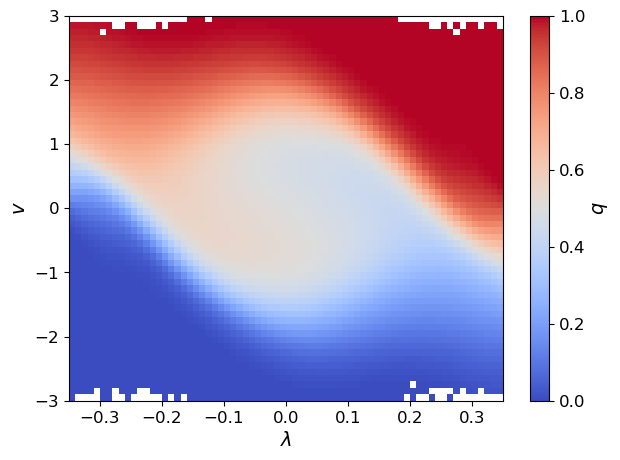

In [9]:
r = cp.asnumpy(q.r_traj)
edges_l = np.linspace(lambda_a, lambda_b, 71)
edges_v = np.linspace(-3, 3, 61)
n, _, _ = np.histogram2d(lam, v, [edges_l, edges_v])
s, _, _ = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)
q_lv = np.where(n > 20, s / np.maximum(n, 1), np.nan)

fig, ax = plt.subplots(1, 1, figsize=(7, 5))
im = ax.pcolormesh(edges_l, edges_v, q_lv.T, cmap='coolwarm', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label='$q$')
ax.set(xlabel='$\\lambda$', ylabel='$v$')
plt.show()

## 7. Save Results

Uncomment to save the raw committor trajectory to disk.

In [9]:
np.save('q_traj_langevin_env0.001g0.2.npy', cp.asnumpy(q.r_traj))